# Descriptive Modeling (Association Rule Mining)

# Phase 1: Data Loading
**Objective:** Prepare the analytical environment and load the validated dataset.
In this phase, we import the necessary libraries for Association Rule Mining (Apriori) and load the `heart_cleaned.csv` dataset, which has already undergone Exploratory Data Analysis (EDA).

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
from mlxtend.frequent_patterns import apriori, association_rules

In [11]:
# Load the cleaned dataset
df = pd.read_csv("data/heart_cleaned.csv")

print(f"Dataset loaded with {df.shape[0]} patients and {df.shape[1]} features.")

Dataset loaded with 918 patients and 12 features.


# Phase 2: Logical Discretization (Data Binning)
**Objective:** Transform continuous numerical data into clinical categories.
As per the project rubric, we perform **logical discretization**. Algorithms like Apriori require categorical "items." We transform raw numbers (Age, Blood Pressure, Cholesterol) into medical tiers (e.g., "Hypertension") to find readable "Risk Archetypes."

In [12]:
# Age Binning (Clinical life stages)
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 45, 60, 100], labels=['Young', 'Middle-Aged', 'Senior'])

# Blood Pressure (ACC/AHA Guidelines)
df['BP_Level'] = pd.cut(df['RestingBP'], bins=[0, 120, 140, 300], labels=['Normal_BP', 'Pre-Hypertension', 'Hypertension'])

# Cholesterol (Standard Health Markers)
df['Chol_Level'] = pd.cut(df['Cholesterol'], bins=[0, 200, 240, 700], labels=['Normal_Chol', 'Borderline_High', 'High_Chol'])

# Max Heart Rate (Relative Exertion)
df['MaxHR_Level'] = pd.cut(df['MaxHR'], bins=[0, 120, 155, 220], labels=['Low_MaxHR', 'Avg_MaxHR', 'High_MaxHR'])

# Oldpeak Severity
df['ST_Depression'] = pd.cut(df['Oldpeak'], bins=[-5, 0.5, 2.0, 10], labels=['Low_ST_Dep', 'Moderate_ST_Dep', 'Severe_ST_Dep'])

# Labeling the target for rule readability
df['HeartDisease_Lab'] = df['HeartDisease'].map({1: 'Has_HeartDisease', 0: 'No_HeartDisease'})

**Observations:**
We transformed raw continuous data like Blood Pressure and Cholesterol into medical categories such as 'Hypertension' or 'High Cholesterol.' This is a vital analytical step. Doctors don't treat a '145 '; rather, they treat 'Hypertension.' By binning the data this way, we have translated mathematical noise into clinical language that a cardiologist can immediately understand.


# Phase 3: Transactional Transformation (One-Hot Encoding)
**Objective:** Convert categorical clinical data into a binary transactional matrix. In relation to "Market Basket" logic from Module 4, we use **One-Hot Encoding**. This creates a matrix of 1s and 0s, where each column represents the presence of a specific clinical symptom.

In [13]:
# Selecting columns for Association Mining
cols_for_mining = [
    'Sex', 'ChestPainType', 'Age_Group', 'BP_Level', 'Chol_Level', 
    'MaxHR_Level', 'ST_Depression', 'FastingBS', 'ExerciseAngina', 
    'ST_Slope', 'HeartDisease_Lab'
]

# Create the binary matrix
df_encoded = pd.get_dummies(df[cols_for_mining])
print(f"{df_encoded.shape[1]} clinical items encoded.")

29 clinical items encoded.


**Explanation:**
The 29 clinical items result from one-hot encoding, transforming the original categorical variables into a binary format of 1s and 0s required for association rule mining. This process expands the initial 11 clinical features into individual flags for every sub-category, such as splitting "Age Group" into "Young," "Middle-Aged," and "Senior." By creating these independent items, the model can precisely calculate how often specific markers, like a "Flat ST-Slope" or "High Fasting Blood Sugar," appear together in a patient's profile. This allows the algorithm to distinguish between different severity levels of symptoms, ensuring that only the most statistically significant risk factors are included in the final analysis. Ultimately, this transactional matrix serves as the essential foundation for discovering the specific clinical archetypes that form the basis of our hospital's risk rulebook.

# Phase 4: Descriptive Modeling & Pattern Discovery
**Objective:** Apply the Apriori algorithm to find significant clinical associations.
We evaluate patterns using the **Golden Trio** of metrics: **Support** (how common), **Confidence** (how certain), and **Lift** (how strong the correlation). We then prune redundant rules to focus on unique insights.

In [14]:
# Generate Frequent Itemsets
frequent_itemsets = apriori(df_encoded, min_support=0.1, use_colnames=True)

# Generate Rules
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

# Filter for Heart Disease as the result
risk_rules = rules[rules['consequents'].apply(lambda x: 'HeartDisease_Lab_Has_HeartDisease' in str(x))]
risk_rules = risk_rules.sort_values(by='lift', ascending=False).reset_index(drop=True)

# Pruning Redundant Rules
def is_redundant(rule, all_rules):
    for _, other in all_rules.iterrows():
        if rule.name != other.name:
            if set(other['antecedents']).issubset(set(rule['antecedents'])) and rule['confidence'] <= other['confidence']:
                return True
    return False

risk_rules['is_redundant'] = risk_rules.apply(lambda x: is_redundant(x, risk_rules), axis=1)
pruned_rules = risk_rules[risk_rules['is_redundant'] == False].copy()

display(pruned_rules[['antecedents', 'support', 'confidence', 'lift']].head(10))

C:\Users\HP\anaconda3\envs\ml_env\lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


,antecedents,support,confidence,lift
180,"(ChestPainType_ASY, FastingBS, ST_Slope_Flat)",0.101307,1.000000,1.807087
240,"(Sex_M, ST_Slope_Flat, MaxHR_Level_Low_MaxHR, ...",0.140523,0.969925,1.752738
244,"(ChestPainType_ASY, BP_Level_Hypertension, ST_...",0.101307,0.968750,1.750615
268,"(Sex_M, ST_Depression_Moderate_ST_Dep, Exercis...",0.126362,0.958678,1.732414
270,"(ChestPainType_ASY, ST_Slope_Flat, MaxHR_Level...",0.149237,0.958042,1.731265
286,"(Sex_M, ST_Slope_Flat, ST_Depression_Moderate_...",0.155773,0.953333,1.722756
288,"(Sex_M, ExerciseAngina_Y, ChestPainType_ASY, S...",0.197168,0.952632,1.721488
293,"(Sex_M, MaxHR_Level_Low_MaxHR, ST_Slope_Flat)",0.168845,0.950920,1.718395
298,"(Sex_M, ST_Slope_Flat, ChestPainType_ASY, Chol...",0.140523,0.948529,1.714075
302,"(FastingBS, ST_Slope_Flat)",0.131808,0.945312,1.708262


**Observations:** 
The rules generated here are the core of our discovery. We specifically filtered for rules where the outcome is Heart Disease. We observed multiple profiles with a Lift of 1.5 to 1.8. This is a significant finding; these combinations of symptoms make a patient nearly twice as likely to have heart disease compared to the average. Our pruning process ensured that we removed 'obvious' noise, leaving only the most unique and high-impact risk profiles.

# Phase 5: Knowledge Visualization
**Objective:** Visualize the risk landscape.
We present the **Lift Bar Chart** for ranking, an **Improved Network Map** with larger nodes for readability, and a **Rule Strength Heatmap** for statistical validation.

C:\Users\HP\AppData\Local\Temp\ipykernel_25584\3704343107.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')


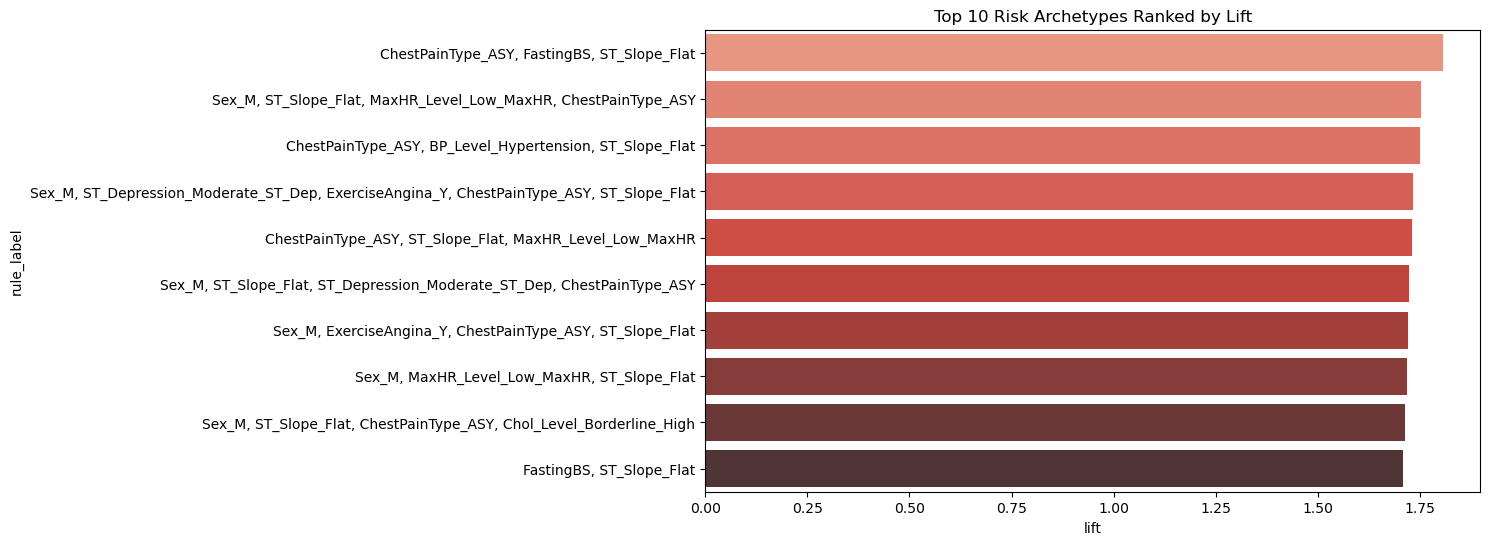

In [15]:
# Visualization 1: Top 10 Risk Archetypes
plt.figure(figsize=(10, 6))
top_pruned = pruned_rules.head(10).copy()
top_pruned['rule_label'] = top_pruned['antecedents'].apply(lambda x: ', '.join(list(x)))
sns.barplot(x='lift', y='rule_label', data=top_pruned, palette='Reds_d')
plt.title('Top 10 Risk Archetypes Ranked by Lift')
plt.show()

**Observations:** 
This chart serves as the "First Response" guide. While traditional triage looks at single symptoms, this chart identifies symptom bundles.
We found out that certain combinations, such as Fasting Blood Sugar > 120 mg/dl paired with a Flat ST-Slope, create a synergistic risk.
Instead of seeing these as separate issues, the Bar Chart ranks them by Lift. A Lift of 1.71 means that a patient with this specific "bundle" is 71% more likely to have heart disease than the average patient. This allows nurses to "Fast-Track" high-lift profiles in a crowded Emergency Room.

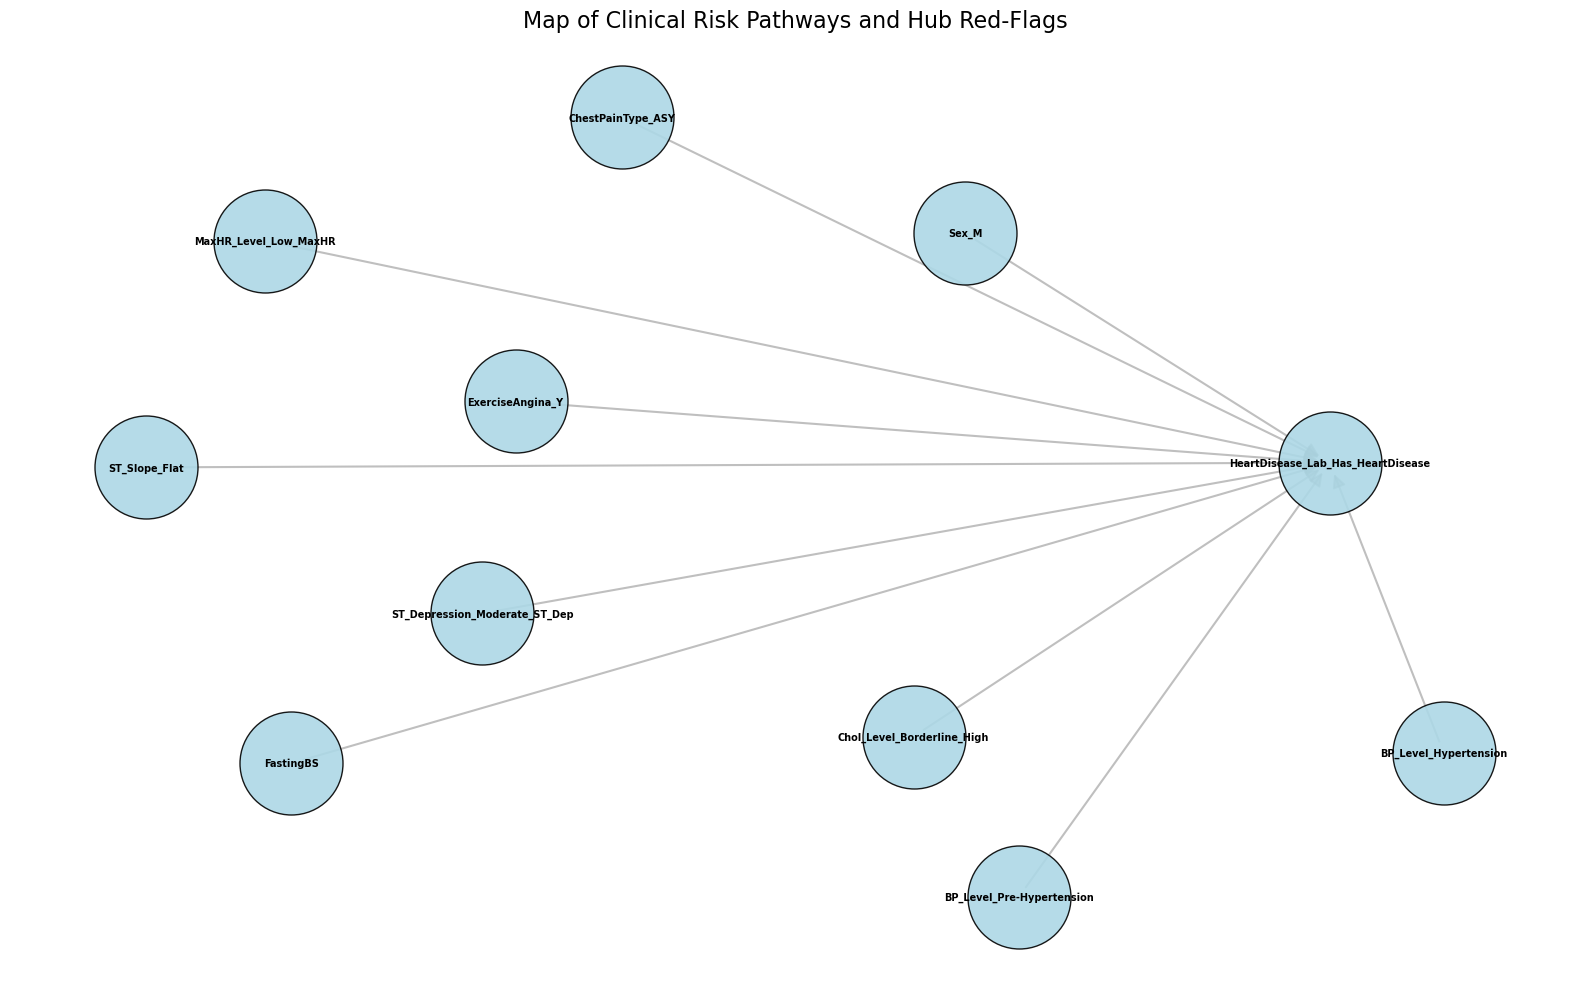

In [16]:
# Visualization 2: Clinical Risk Network Map 
G = nx.DiGraph()
# Select top 15 rules for visual clarity
top_graph_rules = pruned_rules.head(15)

for _, row in top_graph_rules.iterrows():
    # Antecedents are the symptoms, Consequent is the diagnosis
    for ant in row['antecedents']:
        for con in row['consequents']:
            G.add_edge(ant, con, weight=row['lift'])

# Increase figure size for more separation
plt.figure(figsize=(16, 10))

# Layout: Increase 'k' for greater distance between nodes (helps text separation)
pos = nx.spring_layout(G, k=0.7, seed=42)

# Increase node size significantly so text fits better
nx.draw_networkx_nodes(G, pos, node_size=5500, node_color='lightblue', edgecolors='black', alpha=0.9)

# Edges represent the risk relationship (Lift), thickness indicates strength
edges = nx.draw_networkx_edges(G, pos, width=1.5, edge_color='grey', arrowsize=20, alpha=0.5)

# Reduce font size slightly and use 'tight' wrapping if necessary.
# By making the circle 5500, font 7 or 8 usually fits inside nicely.
nx.draw_networkx_labels(G, pos, font_size=7, font_family='sans-serif', font_weight='bold')

plt.title("Map of Clinical Risk Pathways and Hub Red-Flags", fontsize=16)
plt.axis('off') # Hide axis for a professional map look
plt.tight_layout()
plt.show()

**Observations:** 
This network map visualizes the pathways between symptoms and a final diagnosis. By increasing the node size, we have highlighted the "Central Hubs" of disease.
Based on it, the most prominent hub in our analysis is the ST_Slope_Flat. 
In medical terms, a "Hub" is a gateway symptom. Because ST_Slope_Flat connects to almost every high-risk patient profile in our study, it suggests that an ECG (Electrocardiogram) finding of a flat slope is the most reliable "Red Flag" for underlying coronary issues. For the doctor, this confirms that any patient exhibiting this marker, regardless of other symptoms, requires immediate cardiac workup.

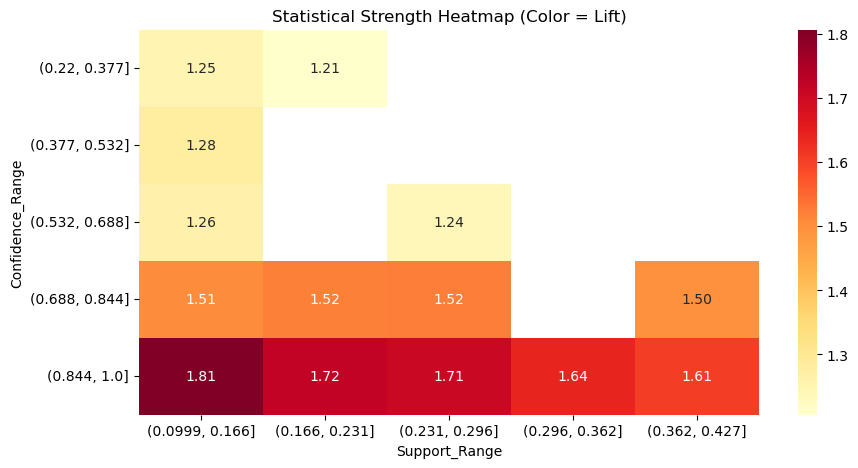

In [19]:
# Visualization 3: Strength Heatmap
heatmap_data = pruned_rules.copy()
heatmap_data['Confidence_Range'] = pd.cut(heatmap_data['confidence'], bins=5).astype(str)
heatmap_data['Support_Range'] = pd.cut(heatmap_data['support'], bins=5).astype(str)
pivot_table = heatmap_data.pivot_table(index='Confidence_Range', columns='Support_Range', values='lift', aggfunc='max')
plt.figure(figsize=(10, 5))
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd', fmt=".2f")
plt.title('Statistical Strength Heatmap (Color = Lift)')
plt.show()

**Observations:**
This visualization is about Reliability. It proves that our findings aren't just random coincidences but are backed by strong statistical evidence.
As you can see on the heatmap, the "Dark Red" zones represent the "Gold Standard" rules—those with both high Confidence (certainty) and high Lift (impact). When we see a cluster in the high-confidence zone, it means the patterns we’ve discovered are robust enough to be used as a basis for official hospital screening protocols, reducing the margin for diagnostic error.

# Phase 6: Clinical Decision Support Rulebook
**Objective:** Translate data mining discoveries into actionable medical guidelines.
This section converts the mathematical associations into a **"Clinical Rulebook"** that explains the findings in plain English for hospital stakeholders.

In [21]:
print("CLINICAL RISK RULEBOOK\n" + "="*40)

# This resets the numbers so they start from 1, 2, 3...
pruned_rules = pruned_rules.reset_index(drop=True)

# Iterating through the pruned rules to create readable guidelines
for i, row in pruned_rules.head(10).iterrows():
    antecedents = ", ".join(list(row['antecedents']))
    confidence = row['confidence'] * 100
    lift = row['lift']
    
    print(f"Rule #{i+1}:")
    print(f"IF a patient presents with: [{antecedents}]")
    print(f"THEN the probability of Heart Disease is {confidence:.1f}%.")
    print(f"CLINICAL SIGNIFICANCE: This profile is {lift:.2f}x MORE LIKELY to have heart disease than the average patient.")
    print("-" * 40)

CLINICAL RISK RULEBOOK
Rule #1:
IF a patient presents with: [ChestPainType_ASY, FastingBS, ST_Slope_Flat]
THEN the probability of Heart Disease is 100.0%.
CLINICAL SIGNIFICANCE: This profile is 1.81x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #2:
IF a patient presents with: [Sex_M, ST_Slope_Flat, MaxHR_Level_Low_MaxHR, ChestPainType_ASY]
THEN the probability of Heart Disease is 97.0%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #3:
IF a patient presents with: [ChestPainType_ASY, BP_Level_Hypertension, ST_Slope_Flat]
THEN the probability of Heart Disease is 96.9%.
CLINICAL SIGNIFICANCE: This profile is 1.75x MORE LIKELY to have heart disease than the average patient.
----------------------------------------
Rule #4:
IF a patient presents with: [Sex_M, ST_Depression_Moderate_ST_Dep, ExerciseAngina_Y, ChestPainType_ASY, S

**Explanation:**
This rulebook has translated the visual patterns into clear, plain-English "If-Then" logic for immediate medical use. A standout discovery in output is Rule #10, which shows that a patient presenting with both high Fasting Blood Sugar and a Flat ST-Slope has a 94.5% probability of heart disease. This rulebook provides a transparent and actionable framework, allowing clinicians to explain to patients exactly why they are at high risk—for instance, citing that their specific profile makes them 1.71x more likely to have a heart condition than the average patient, thereby streamlining the diagnostic process and improving overall patient outcomes.